# 07 Maps

Two maps of the Slantsy catchment from notebook 06 (base scenario, central distance decay):

1. a static hero map for the README (`figures/07_hero_map.png`);
2. an interactive map for GitHub Pages (`docs/klint_visitor_map.html`).

The new complex does not have its own point yet. As in 06, it sits at the existing Slantsy museum: both are in the town centre on the Plyussa riverfront, a few minutes apart by car. Colours: violet for the model, orange only for Slantsy.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter, binary_fill_holes
from scipy.spatial import cKDTree

CRS = 32636
NEW_SITE_PROXY = "Slantsy Local History Museum"  # new complex placed at the existing museum

MAIN, MID, LIGHT = "#6a51a3", "#756bb1", "#bcbddc"
PURPLES = ["#f2f0f7", "#cbc9e2", "#9e9ac8", "#756bb1", "#54278f"]
ORANGE, DARK = "#FF9354", "#333333"
GREY, LIGHT_GREY, DARK_GREY = "#999999", "#d9d9d9", "#555555"
HALO = [pe.withStroke(linewidth=3, foreground="white")]

study = gpd.read_file("../data/processed/study_area.geojson").to_crs(CRS)
catch = pd.read_csv("../data/processed/catchment_slantsy.csv")
geo = pd.read_csv("../data/processed/attractions_geo.csv")
attr = pd.read_csv("../data/attractions.csv")
sites = pd.read_csv("../data/processed/calibration_sites.csv")

# role from attractions.csv: the one in attractions_geo.csv predates the Sablino change
attractions = (geo.drop(columns="role")
                  .merge(attr[["name_en", "role"]], on="name_en", how="left")
                  .merge(sites[["name_en", "visitors", "year", "factor_C"]], on="name_en", how="left"))
attractions = gpd.GeoDataFrame(
    attractions, geometry=gpd.points_from_xy(attractions.lon, attractions.lat), crs=4326
).to_crs(CRS)
assert attractions["role"].notna().all(), "role missing for some attraction"
assert NEW_SITE_PROXY in set(attractions["name_en"])

print(f"{len(catch):,} origins, {catch['visits'].sum():,.0f} visits a year (base scenario)")
print(attractions.groupby("role").size())

3,440 origins, 36,015 visits a year (base scenario)
role
calibration    8
competitor     2
context        3
dtype: int64


In [2]:
# Baltic-Ladoga Klint: schematic line from the Narva river to the Syas river
KLINT_ORDER = ["Ivangorod", "Koporye", "Dudergof heights", "Pulkovo heights",
               "Sablino", "Putilovo", "Staraya Ladoga", "Syas river"]
KLINT_MANUAL = {  # lat, lon set by hand, approximate
    "Dudergof heights": (59.70, 30.13),
    "Pulkovo heights": (59.77, 30.33),
    "Syas river": (60.05, 32.55),
}

def site_lonlat(key):
    row = geo[geo["name_en"].str.contains(key, case=False)]
    assert len(row) == 1, f"{key}: {len(row)} matches"
    return row["lon"].iloc[0], row["lat"].iloc[0]

def chaikin(c, n=3):  # rounds the corners of a polyline
    for _ in range(n):
        q = 0.75 * c[:-1] + 0.25 * c[1:]
        r = 0.25 * c[:-1] + 0.75 * c[1:]
        c = np.vstack([c[0], np.column_stack([q, r]).reshape(-1, 2), c[-1]])
    return c

lonlat = [KLINT_MANUAL[k][::-1] if k in KLINT_MANUAL else site_lonlat(k) for k in KLINT_ORDER]
kpts = gpd.GeoSeries(gpd.points_from_xy(*zip(*lonlat)), crs=4326).to_crs(CRS)
klint = gpd.GeoSeries([shapely.LineString(chaikin(np.c_[kpts.x, kpts.y]))], crs=CRS)
print(f"Klint line about {klint.length.iloc[0] / 1000:.0f} km")

Klint line about 264 km


## Static hero map

Bands show car travel time to Slantsy. Travel times of the 3,440 origins are put onto a 1 km grid and lightly smoothed, so band edges are approximate (a few km). Water (the Gulf of Finland, Lake Ladoga) is left white; empty areas inside the land are filled in. The legend gives the share of modelled day-trip visits (base scenario) that comes from each band. Model sites are sized by annual attendance. The existing Slantsy museum is one of them, hidden under the orange marker for the new complex.

The Baltic-Ladoga Klint is drawn as a schematic line through places on its edge (Ivangorod, Koporye, Dudergof and Pulkovo heights, Sablino, Putilovo, Staraya Ladoga) to the Syas river. It shows the general course, not the exact edge of the plateau.

band
under 1 h    0.131
1-2 h        0.101
2-3 h        0.325
3-4 h        0.427
over 4 h     0.015
Name: visits, dtype: float64


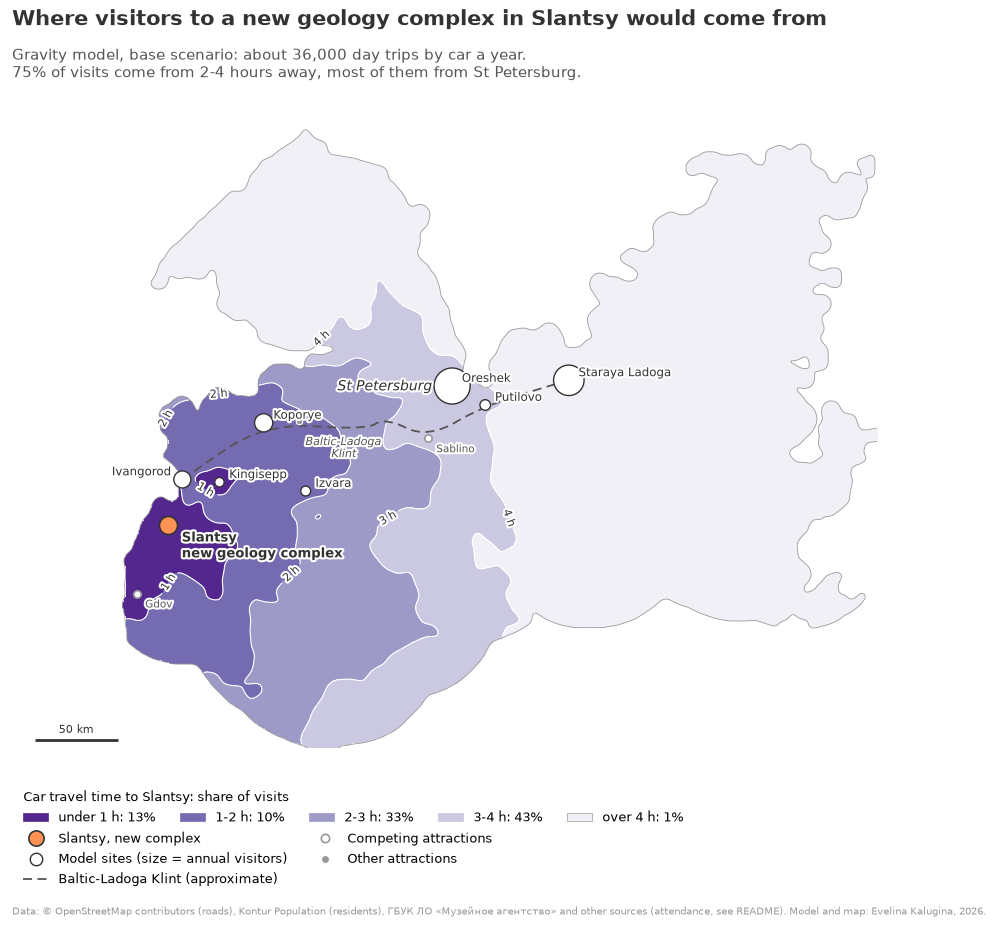

In [7]:
BANDS = [0, 60, 120, 180, 240, 10_000]
BAND_NAMES = ["under 1 h", "1-2 h", "2-3 h", "3-4 h", "over 4 h"]
BAND_COLORS = PURPLES[::-1]  # dark = close to Slantsy
KLINT_DASH = (0, (5, 3))

catch["band"] = pd.cut(catch["time_min"], BANDS, labels=BAND_NAMES, right=False)
total = catch["visits"].sum()
share = catch.groupby("band", observed=False)["visits"].sum() / total
print(share.round(3))

# travel time on a 1 km grid, smoothed
xmin, ymin, xmax, ymax = study.total_bounds
STEP = 1_000
gx, gy = np.meshgrid(np.arange(xmin, xmax, STEP), np.arange(ymin, ymax, STEP))
pts = catch[["x", "y"]].to_numpy()
tt = griddata(pts, catch["time_min"], (gx, gy), method="linear")
tt = np.where(np.isnan(tt), griddata(pts, catch["time_min"], (gx, gy), method="nearest"), tt)
tt = gaussian_filter(tt, sigma=3)

# land = near populated cells; holes enclosed by land are filled, so only the gulf and Ladoga stay white
dist, _ = cKDTree(pts).query(np.c_[gx.ravel(), gy.ravel()])
populated = (dist.reshape(gx.shape) <= 6_000) & shapely.contains_xy(study.union_all(), gx, gy)
populated = binary_fill_holes(populated)
land = gaussian_filter(populated.astype(float), sigma=2)
tt = np.ma.masked_where(land < 0.5, tt)

fig, ax = plt.subplots(figsize=(10, 9.5))
fig.subplots_adjust(left=0.03, right=0.97, top=0.86, bottom=0.17)

ax.contourf(gx, gy, tt, levels=BANDS, colors=BAND_COLORS, zorder=1)
cs = ax.contour(gx, gy, tt, levels=BANDS[1:-1], colors="white", linewidths=0.8, zorder=2)
for txt in ax.clabel(cs, fmt=lambda v: f"{v / 60:.0f} h", fontsize=8, inline=True):
    txt.set_color(DARK)
    txt.set_path_effects(HALO)
ax.contour(gx, gy, land, levels=[0.5], colors=GREY, linewidths=0.6, zorder=3)

klint.plot(ax=ax, color=DARK_GREY, linewidth=1.3, linestyle=KLINT_DASH, zorder=3.5)
kp = klint.iloc[0].interpolate(0.4, normalized=True)  # between Koporye and St Petersburg
ax.annotate("Baltic-Ladoga\nKlint", (kp.x, kp.y), xytext=(0, -6), textcoords="offset points",
            fontsize=8, style="italic", color=DARK_GREY, ha="center", va="top",
            linespacing=1.0, path_effects=HALO, zorder=7)

others = attractions[attractions["name_en"] != NEW_SITE_PROXY]
ctx = others[others["role"] == "context"]
ax.scatter(ctx.geometry.x, ctx.geometry.y, s=22, color=GREY, edgecolor="white", linewidth=0.8, zorder=4)
comp = others[others["role"] == "competitor"]
ax.scatter(comp.geometry.x, comp.geometry.y, s=28, color="white", edgecolor=GREY, linewidth=1.2, zorder=5)
for _, r in comp.iterrows():
    name = next((k for k in ["Sablino", "Gdov"] if k.lower() in r["name_en"].lower()), r["name_en"])
    ax.annotate(name, (r.geometry.x, r.geometry.y), xytext=(6, -10), textcoords="offset points",
                fontsize=7.5, color=DARK_GREY, path_effects=HALO, zorder=7)
cal = others[others["role"] == "calibration"].sort_values("visitors", ascending=False)
ax.scatter(cal.geometry.x, cal.geometry.y, s=15 + cal["visitors"] / 300, color="white",
           edgecolor=DARK, linewidth=1, zorder=6)

KEYS = ["Oreshek", "Staraya Ladoga", "Koporye", "Ivangorod", "Kingisepp", "Izvara", "Putilovo"]
OFFSETS = {"Ivangorod": (-7, 3, "right"), "Kingisepp": (7, 3, "left")}
for _, r in cal.iterrows():
    key = next((k for k in KEYS if k.lower() in r["name_en"].lower()), None)
    if key is None:
        print("no label for:", r["name_en"])
        continue
    dx, dy, ha = OFFSETS.get(key, (7, 3, "left"))
    ax.annotate(key, (r.geometry.x, r.geometry.y), xytext=(dx, dy), textcoords="offset points",
                fontsize=8.5, color=DARK, ha=ha, path_effects=HALO, zorder=7)

spb = gpd.GeoSeries(gpd.points_from_xy([30.315], [59.939]), crs=4326).to_crs(CRS).iloc[0]
ax.text(spb.x, spb.y, "St Petersburg", fontsize=10, style="italic", color=DARK,
        ha="center", va="center", path_effects=HALO, zorder=7)

sl = attractions.loc[attractions["name_en"] == NEW_SITE_PROXY].geometry.iloc[0]
ax.scatter(sl.x, sl.y, s=170, color=ORANGE, edgecolor=DARK, linewidth=1.2, zorder=8)
ax.annotate("Slantsy\nnew geology complex", (sl.x, sl.y), xytext=(10, -4), textcoords="offset points",
            fontsize=9.5, fontweight="bold", color=DARK, va="top", path_effects=HALO, zorder=9)

ax.set_xlim(xmin - 10_000, xmax + 10_000)
ax.set_ylim(ymin - 10_000, ymax + 10_000)
ax.set_aspect("equal")
ax.set_axis_off()
x0, y0 = xmin + 5_000, ymin + 5_000
ax.plot([x0, x0 + 50_000], [y0, y0], color=DARK, linewidth=2, solid_capstyle="butt")
ax.text(x0 + 25_000, y0 + 4_000, "50 km", ha="center", fontsize=8, color=DARK)

fig.text(0.06, 0.965, "Where visitors to a new geology complex in Slantsy would come from",
         fontsize=15, fontweight="bold", color=DARK, ha="left", va="top")
fig.text(0.06, 0.925,
         f"Gravity model, base scenario: about {round(total, -3):,.0f} day trips by car a year.\n"
         f"{share['2-3 h'] + share['3-4 h']:.0%} of visits come from 2-4 hours away, "
         "most of them from St Petersburg.",
         fontsize=10.5, color=DARK_GREY, ha="left", va="top")

band_handles = [Patch(facecolor=c, edgecolor=GREY if i == len(BAND_COLORS) - 1 else c,
                      linewidth=0.5, label=f"{n}: {share[n]:.0%}")
                for i, (c, n) in enumerate(zip(BAND_COLORS, BAND_NAMES))]
fig.legend(handles=band_handles, title="Car travel time to Slantsy: share of visits",
           loc="lower left", bbox_to_anchor=(0.06, 0.095), ncol=5, frameon=False,
           fontsize=9, title_fontsize=9, alignment="left")

site_handles = [
    Line2D([0], [0], marker="o", ls="", markersize=11, markerfacecolor=ORANGE,
           markeredgecolor=DARK, markeredgewidth=1.2, label="Slantsy, new complex"),
    Line2D([0], [0], marker="o", ls="", markersize=9, markerfacecolor="white",
           markeredgecolor=DARK, label="Model sites (size = annual visitors)"),
    Line2D([0], [0], color=DARK_GREY, linewidth=1.3, linestyle=KLINT_DASH,
           label="Baltic-Ladoga Klint (approximate)"),
    Line2D([0], [0], marker="o", ls="", markersize=6, markerfacecolor="white",
           markeredgecolor=GREY, markeredgewidth=1.2, label="Competing attractions"),
    Line2D([0], [0], marker="o", ls="", markersize=6, markerfacecolor=GREY,
           markeredgecolor="white", label="Other attractions"),
]
fig.legend(handles=site_handles, loc="lower left", bbox_to_anchor=(0.06, 0.03), ncol=2,
           frameon=False, fontsize=9)

fig.text(0.06, 0.012,
         "Data: © OpenStreetMap contributors (roads), Kontur Population (residents), "
         "ГБУК ЛО «Музейное агентство» and other sources (attendance, see README). "
         "Model and map: Evelina Kalugina, 2026.",
         fontsize=7.5, color=GREY, ha="left")

fig.savefig("../figures/07_hero_map.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## Interactive map

The same travel-time bands as the hero map, as polygons on a web map, plus the cells that send at least one visit a year (circle size = visits) and the attractions. Click any circle for details. Saved to `docs/klint_visitor_map.html` and published with GitHub Pages.

In [4]:
import json
import folium
from rasterio import features
from rasterio.transform import Affine

# bands from the hero-map grid, as polygons
idx = np.digitize(tt.data, BANDS[1:-1]).astype("uint8")
idx[np.ma.getmaskarray(tt)] = 255
idx = np.flipud(idx)  # raster rows run top to bottom
transform = Affine(STEP, 0, gx.min() - STEP / 2, 0, -STEP, gy.max() + STEP / 2)
bands = gpd.GeoDataFrame(
    [{"band": BAND_NAMES[int(v)], "geometry": shapely.geometry.shape(g)}
     for g, v in features.shapes(idx, mask=idx != 255, transform=transform)],
    crs=CRS,
).dissolve("band").reset_index()
bands["geometry"] = bands.simplify(400)
bands["share_txt"] = bands["band"].map(share).map(lambda s: f"{s:.0%}")
bands = bands.to_crs(4326)
band_color = dict(zip(BAND_NAMES, BAND_COLORS))

vr = pd.read_csv("../data/processed/visitors_range.csv", index_col=[0, 1])
trips = vr.loc[("museum", "day_trips_model")]
museum = vr.loc[("museum", "museum_total")]

m = folium.Map(location=[59.6, 30.6], zoom_start=8, tiles=None, control_scale=True)
ESRI = "https://server.arcgisonline.com/ArcGIS/rest/services/"
folium.TileLayer(ESRI + "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
                 attr="Esri, © OpenStreetMap contributors", name="Light grey").add_to(m)
folium.TileLayer(ESRI + "World_Street_Map/MapServer/tile/{z}/{y}/{x}",
                 attr="Esri, © OpenStreetMap contributors", name="Streets").add_to(m)

fg_bands = folium.FeatureGroup(name="Car travel time to Slantsy")
folium.GeoJson(
    json.loads(bands.to_json()),
    style_function=lambda f: {"fillColor": band_color[f["properties"]["band"]],
                              "color": "white", "weight": 0.6, "fillOpacity": 0.45},
    tooltip=folium.GeoJsonTooltip(fields=["band", "share_txt"],
                                  aliases=["Car time to Slantsy", "Share of visits"]),
).add_to(fg_bands)
fg_bands.add_to(m)

fg_klint = folium.FeatureGroup(name="Baltic-Ladoga Klint")
kline = [(y, x) for x, y in klint.to_crs(4326).iloc[0].coords]
folium.PolyLine(kline, color=DARK_GREY, weight=2, dash_array="6 4",
                tooltip="Baltic-Ladoga Klint (approximate line): the edge of the limestone plateau, "
                        "from the Narva river to the Syas river").add_to(fg_klint)
fg_klint.add_to(m)

fg_cells = folium.FeatureGroup(name="Where visitors come from")
for _, r in catch[catch["visits"] >= 1].sort_values("visits", ascending=False).iterrows():
    popup = (f"<b>{r['region']}</b><br>Residents: {r['population']:,.0f}<br>"
             f"Car time to Slantsy: {r['time_min']:.0f} min<br>"
             f"Visits a year: {r['visits']:,.0f} ({r['per_1000']:.1f} per 1,000 residents)")
    folium.CircleMarker([r["lat"], r["lon"]], radius=2 + np.sqrt(r["visits"]) * 0.6,
                        color=DARK, weight=0.5, fill=True, fill_color=MAIN, fill_opacity=0.7,
                        popup=folium.Popup(popup, max_width=260)).add_to(fg_cells)
fg_cells.add_to(m)

ROLE_TEXT = {"calibration": "Model site", "competitor": "Competing attraction", "context": "Other attraction"}
fg_attr = folium.FeatureGroup(name="Attractions")
for _, r in attractions[attractions["name_en"] != NEW_SITE_PROXY].to_crs(4326).iterrows():
    if r["role"] == "calibration":
        popup = (f"<b>{r['name_en']}</b><br>{ROLE_TEXT[r['role']]}<br>"
                 f"Visitors: {r['visitors']:,.0f} ({r['year']:.0f})<br>"
                 f"Observed vs model: ×{r['factor_C']:.2f}")
        style = dict(radius=4 + np.sqrt(r["visitors"]) / 40, color=DARK, weight=1.2,
                     fill_color="white", fill_opacity=1)
    else:
        popup = f"<b>{r['name_en']}</b><br>{ROLE_TEXT[r['role']]} (not used to fit the model)"
        style = dict(radius=4, color=GREY, weight=1.2, fill_color="white" if r["role"] == "competitor" else GREY,
                     fill_opacity=1)
    folium.CircleMarker([r.geometry.y, r.geometry.x], fill=True, tooltip=r["name_en"],
                        popup=folium.Popup(popup, max_width=260), **style).add_to(fg_attr)
fg_attr.add_to(m)

sl_ll = attractions.loc[attractions["name_en"] == NEW_SITE_PROXY].to_crs(4326).geometry.iloc[0]
popup = ("<b>Slantsy: new geology museum and research institute</b><br>"
         f"Day trips by car a year: {trips['low']:,.0f} / <b>{trips['base']:,.0f}</b> / {trips['high']:,.0f}<br>"
         f"Museum total with tourists: {museum['low']:,.0f} / <b>{museum['base']:,.0f}</b> / {museum['high']:,.0f}<br>"
         "<i>low / base / high scenario</i>")
fg_sl = folium.FeatureGroup(name="Slantsy, new complex")
folium.CircleMarker([sl_ll.y, sl_ll.x], radius=10, color=DARK, weight=1.5, fill=True,
                    fill_color=ORANGE, fill_opacity=1, popup=folium.Popup(popup, max_width=300),
                    tooltip=folium.Tooltip("Slantsy", permanent=True, direction="right")).add_to(fg_sl)
fg_sl.add_to(m)

band_rows = "".join(
    f'<div><span style="display:inline-block;width:14px;height:10px;background:{band_color[n]};'
    f'border:1px solid #ccc;margin-right:6px"></span>{n}: {share[n]:.0%}</div>' for n in BAND_NAMES)
dot = ('<span style="display:inline-block;width:{s}px;height:{s}px;border-radius:50%;background:{f};'
       'border:1.5px solid {e};margin-right:6px;vertical-align:middle"></span>')
line = (f'<span style="display:inline-block;width:18px;border-top:2px dashed {DARK_GREY};'
        'margin-right:6px;vertical-align:middle"></span>')
legend = f"""
<div style="position:fixed;top:12px;right:12px;z-index:9999;background:white;padding:10px 12px;
            border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.3);font:12px sans-serif;color:{DARK};max-width:260px">
  <b>Visitors to a new geology complex in Slantsy</b><br>
  <span style="color:{DARK_GREY}">Gravity model, base scenario, day trips by car</span>
  <div style="margin-top:6px"><b>Car time to Slantsy: share of visits</b></div>
  {band_rows}
  <div style="margin-top:6px">{dot.format(s=12, f=ORANGE, e=DARK)}Slantsy, new complex</div>
  <div>{dot.format(s=10, f=MAIN, e=DARK)}Visits from a 5 km cell (size)</div>
  <div>{dot.format(s=10, f="white", e=DARK)}Model sites (size = visitors)</div>
  <div>{line}Baltic-Ladoga Klint (approximate)</div>
  <div>{dot.format(s=8, f="white", e=GREY)}Competing attractions</div>
  <div>{dot.format(s=8, f=GREY, e=GREY)}Other attractions</div>
  <div style="margin-top:6px;color:{GREY};font-size:10px">Data: © OpenStreetMap contributors, Kontur Population,
  ГБУК ЛО «Музейное агентство» and other sources. Evelina Kalugina, 2026.</div>
</div>"""
m.get_root().html.add_child(folium.Element(legend))
folium.LayerControl(position="topleft", collapsed=False).add_to(m)

m.save("../docs/klint_visitor_map.html")
print(f"{(catch['visits'] >= 1).sum():,} cells shown")
m

C:\Users\kalug\anaconda3\envs\urban\Lib\site-packages\rasterio\features.py:129: RuntimeWarning: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
  yield from _shapes(source, mask, connectivity, transform)


1,037 cells shown
